# astrovodka TNG-100 HI 观测模拟示例

处理 TNG-100 snapshot 099 (z~0) 的前 50 个子暗晕，
在 z=0, 0.05, 0.1 三个观测红移生成合成 HI 数据立方体。

### 关键改进 (vs astromartini)
| 方面 | astromartini | astrovodka |
|------|-------------|------------|
| 距离 | 线性哈勃定律 | Planck15 宇宙学 |
| HI模型 | 气压分区 | K13 体积模型 |
| 数据加载 | FOF群(慢) | 子暗晕(快) |

In [1]:
import sys
sys.path.insert(0, '/home/zerui603/work/astrovodka/astrovodka.0.1')
sys.path.insert(0, '/home/zerui603/work/astrovodka')

import os, time, json
import numpy as np
import astropy.units as U
import astropy.constants as const
from astropy.cosmology import Planck15
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter
import h5py
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['figure.figsize'] = (16, 5)
print('基础依赖导入成功')

基础依赖导入成功


In [2]:
from astrovodka import Martini, DataCube
from astrovodka.sources import TNGSource, SPHSource
from astrovodka.beams import GaussianBeam
from astrovodka.spectral_models import GaussianSpectrum
from astrovodka.sph_kernels import CubicSplineKernel
from astrovodka.sources._k13_model import compute_HI_mass_particle, calc_UMW_global_Faucher11
from astrovodka.sources._illustris_tools import loadHeader, loadSingle, loadSubset, getSnapOffsets
from astrovodka.cosmology_utils import luminosity_distance, angular_diameter_distance
print('astrovodka 模块导入成功')

astrovodka 模块导入成功


## 配置

| 参数 | 值 | 说明 |
|------|-----|------|
| N_SUBHALOS | 50 | 处理数量 |
| OBSERVED_REDSHIFTS | [0.0, 0.05, 0.1] | 观测红移 |
| PX_SIZE | 10 arcsec | 固定角分辨率(用户要求) |
| load_subhalo_only | True | 仅加载子暗晕粒子(快) |

### 分辨率限制说明

10角秒的固定分辨率意味着：
- z=0 (D_A~0.004 Mpc): 1" = 2e-5 kpc → 整个星系→极小角尺寸
- z=0.05 (D_A~208 Mpc): 1" = 1.01 kpc → 10" = 10.1 kpc
- z=0.1 (D_A~393 Mpc): 1" = 1.90 kpc → 10" = 19.0 kpc

TNG-100星系团中的卫星星系典型尺寸为1-5 kpc。在z=0.05处，
5kpc星系仅占~0.5个像素，在z=0.1处仅占~0.25个像素。
**因此部分小卫星星系在较高红移无法分辨，这是物理上预期的结果。**

In [3]:
basePath = '/data/hw2/projects/FAST/HD2_high/TNG/TNG-100/'
snapNum = 99
OBSERVED_REDSHIFTS = [0.0, 0.05, 0.1]
PX_SIZE = 10.0 * U.arcsec
DATA_DIR = '/data/hw2/projects/FAST/HD2_high/astrovodka/datafile/'
FIG_DIR = '/home/zerui603/work/astrovodka/astrovodka.0.1/examplefigure/'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
N_SUBHALOS = 50
MIN_GAS = 64
MAX_GAS = 5000
cosmo = Planck15

# 打印宇宙学距离
print('宇宙学距离 (Planck15):')
for z in OBSERVED_REDSHIFTS:
    DL = luminosity_distance(z); DA = angular_diameter_distance(z)
    scale = (DA.to(U.kpc) / U.rad).to(U.kpc / U.arcsec)
    print(f'  z={z:.2f}: D_L={DL:.1f}, D_A={DA:.1f}, 1 arcsec = {scale.value:.2f} kpc')

宇宙学距离 (Planck15):
  z=0.00: D_L=0.0 Mpc, D_A=0.0 Mpc, 1 arcsec = 0.00 kpc
  z=0.05: D_L=229.6 Mpc, D_A=208.3 Mpc, 1 arcsec = 1.01 kpc
  z=0.10: D_L=475.3 Mpc, D_A=392.8 Mpc, 1 arcsec = 1.90 kpc


## 数据准备

从 TNG-100 group catalog 筛选气体粒子数 [64, 5000] 的子暗晕。
使用 `load_subhalo_only=True` 仅加载子暗晕粒子（不加载整个 FOF 群）。

In [4]:
print('加载 group catalog...')
header = loadHeader(basePath, snapNum)
h_sim = header['HubbleParam']; a_sim = header['Time']; z_sim = header['Redshift']
print(f'Snapshot {snapNum}: z={z_sim:.6f}, h={h_sim:.4f}')

with h5py.File(basePath + f'/groups_{snapNum:03d}/fof_subhalo_tab_{snapNum:03d}.0.hdf5', 'r') as f:
    n_gas_all = f['Subhalo/SubhaloLenType'][:, 0]
    grnr_all = f['Subhalo/SubhaloGrNr'][:]

# 筛选：气体粒子数在范围内
valid_mask = (n_gas_all >= MIN_GAS) & (n_gas_all <= MAX_GAS)
valid_ids = np.where(valid_mask)[0]
print(f'总子暗晕: {len(n_gas_all):,}, 符合条件 [{MIN_GAS},{MAX_GAS}]: {len(valid_ids)}')

# 取前 N_SUBHALOS 个（无需过滤 group 0，因为使用子暗晕加载模式）
target_ids = valid_ids[:N_SUBHALOS]
target_gas_counts = n_gas_all[target_ids]
target_groups = grnr_all[target_ids]
print(f'选取 {len(target_ids)} 个子暗晕')
print(f'气体粒子范围: {target_gas_counts.min()}-{target_gas_counts.max()}')
print(f'所属 FOF 群: {np.unique(target_groups).tolist()}')
print(f'前 10 个 ID: {target_ids[:10].tolist()}')

加载 group catalog...
Snapshot 99: z=0.000000, h=0.6774
总子暗晕: 17,185, 符合条件 [64,5000]: 117
选取 50 个子暗晕
气体粒子范围: 79-4554
所属 FOF 群: [0]
前 10 个 ID: [7, 8, 17, 18, 26, 27, 28, 29, 32, 36]


## 独立版 K13 函数（用于对比）

逐行复制自 `260529-testHImodel-singleFFT-K13-multiprocess.py`，
包含密度转换、Jeans 长度、面密度计算和 K13 核心模型。

In [5]:
# 物理常数 (CGS)
PROTONMASS=const.m_p.cgs.value; MSUN=const.M_sun.cgs.value; BOLTZMANN=const.k_B.cgs.value
GAMMA=5.0/3.0; GAMMA_MINUS1=GAMMA-1.0; HYDROGEN_MASSFRAC=0.76; Z_SUN=0.0127; kpc_to_cm=3.08568e21

def rho_code_to_physical_std(rho_code,z=0,HUBBLE=0.6774):
    rho_com=rho_code*1e10*const.M_sun*HUBBLE**2/U.kpc**3
    return (rho_com.to(U.g/U.cm**3)*(1.0+z)**3).value

def rho_code_to_nH_std(rho_code,X_H=HYDROGEN_MASSFRAC,z=0,HUBBLE=0.6774):
    rho_phys=rho_code_to_physical_std(rho_code,z,HUBBLE)*U.g/U.cm**3
    return ((X_H*rho_phys/const.m_p).to(1.0/U.cm**3)).value

def calc_Jeans_length_std(u_code,rho_code,z=0,HUBBLE=0.6774):
    u_cgs=u_code*1e10; rho_cgs=rho_code_to_physical_std(rho_code,z,HUBBLE)
    L_J_cm=np.sqrt(GAMMA*GAMMA_MINUS1*u_cgs/(const.G.cgs.value*np.maximum(rho_cgs,1e-40)))
    return L_J_cm/kpc_to_cm

def calc_Sigma_neutral_std(u_code,rho_code,f_neutral_XH,z=0,HUBBLE=0.6774):
    L_J_kpc=calc_Jeans_length_std(u_code,rho_code,z,HUBBLE)
    rho_msun_kpc3=rho_code*1e10*HUBBLE**2*(1.0+z)**3
    return np.maximum(L_J_kpc*rho_msun_kpc3*f_neutral_XH,1e-20)

def get_f_neutral_std(nH_code,sfr_code):
    f_neutral=nH_code.copy(); f_neutral[sfr_code>0.0]=1.0; return f_neutral

def f_mol_K13_vol_std(rho_code,u_code,Z,nH_code,sfr_code,X_H,U_MW,z=0,HUBBLE=0.6774):
    f_neutral=get_f_neutral_std(nH_code,sfr_code)
    n_H=np.maximum(rho_code_to_nH_std(rho_code,X_H,z,HUBBLE),1e-10)
    n_CNM_gas=np.maximum(n_H*f_neutral,1e-10); D_MW=np.maximum(Z/Z_SUN,1e-10)
    n_CNM_2p=23.0*U_MW*4.1/(1.0+3.1*D_MW**0.365); n_CNM=np.maximum(n_CNM_gas,n_CNM_2p)
    chi=7.2*U_MW*(n_CNM/10.0)**(-1.0); chi=np.clip(chi,1e-10,1e10)
    Sigma_neutral=calc_Sigma_neutral_std(u_code,rho_code,f_neutral*X_H,z,HUBBLE)
    Sigma_Msun_pc2=Sigma_neutral*1e-6; f_c=5.0
    tau_c=0.066*f_c*D_MW*np.maximum(Sigma_Msun_pc2,1e-20)
    s=np.log(1.0+0.6*chi+0.01*chi**2)/(0.6*np.maximum(tau_c,1e-20))
    f_mol=np.where(s<2.0,1.0-3.0*s/(4.0+s),0.0); f_mol=np.clip(f_mol,0.0,1.0)
    return f_mol,f_neutral*(1.0-f_mol),f_neutral*f_mol

def compute_HI_mass_std(gas_data,U_MW,z=0,HUBBLE=0.6774):
    rho_code=gas_data['Density'][:].astype('float64')
    u_code=gas_data['InternalEnergy'][:].astype('float64')
    nH_code=gas_data['NeutralHydrogenAbundance'][:].astype('float64')
    sfr_code=gas_data['StarFormationRate'][:].astype('float64')
    gfm=gas_data['GFM_Metals'][:].astype('float64'); X_H=gfm if gfm.ndim==1 else gfm[:,0]
    Z=gas_data['GFM_Metallicity'][:].astype('float64')
    m_gas=gas_data['Masses'][:].astype('float64')
    f_mol,f_HI,f_H2=f_mol_K13_vol_std(rho_code,u_code,Z,nH_code,sfr_code,X_H,U_MW,z=z,HUBBLE=HUBBLE)
    return m_gas*X_H*f_HI,m_gas*X_H*f_H2
print('独立版 K13 函数定义完成')

独立版 K13 函数定义完成


### 子暗晕气体加载

使用 `load_subhalo_only=True` 仅加载子暗晕粒子，速度快。

In [6]:
def load_subhalo_gas(basePath, snapNum, subID):
    data_sub = loadSingle(basePath, snapNum, subhaloID=subID)
    subset_g = getSnapOffsets(basePath, snapNum, subID, 'Subhalo')
    fields = ['Masses','Velocities','InternalEnergy','ElectronAbundance',
              'NeutralHydrogenAbundance','StarFormationRate','Density',
              'CenterOfMass','GFM_Metals','GFM_Metallicity']
    mdi = [None,None,None,None,None,None,None,None,0,None]
    data_g = loadSubset(basePath, snapNum, 'gas', fields=fields, subset=subset_g, mdi=mdi)
    return data_g, data_sub, data_g['count']
print('load_subhalo_gas() 定义完成（子暗晕加载模式）')

load_subhalo_gas() 定义完成（子暗晕加载模式）


## 任务一 & 任务二：批量处理

对每个子暗晕：
1. 加载气体数据
2. 用 astrovodka 和独立版分别计算 K13 质量并对比
3. 在 z=0, 0.05, 0.1 生成数据立方体

In [7]:
results = []; mass_comparisons = []
print(f'处理 {len(target_ids)} 个子暗晕 x {len(OBSERVED_REDSHIFTS)} 个红移')
print(f'预计 {len(target_ids)*len(OBSERVED_REDSHIFTS)} 个 FITS 文件')
t_start = time.time()

for idx, subID in enumerate(tqdm(target_ids, desc='子暗晕')):
    subID = int(subID)
    try:
        data_g, data_sub, n_gas = load_subhalo_gas(basePath, snapNum, subID)
        if n_gas < MIN_GAS: continue

        # 任务二: K13 质量对比
        U_MW_val = calc_UMW_global_Faucher11(z_sim)
        m_HI_a, m_H2_a = compute_HI_mass_particle(data_g, U_MW_val, redshift=z_sim, hubble_h=h_sim)
        m_HI_s, m_H2_s = compute_HI_mass_std(data_g, U_MW_val, z=z_sim, HUBBLE=h_sim)
        hi_astro=np.sum(m_HI_a)*1e10/h_sim; h2_astro=np.sum(m_H2_a)*1e10/h_sim
        hi_std=np.sum(m_HI_s)*1e10/h_sim; h2_std=np.sum(m_H2_s)*1e10/h_sim
        mass_comparisons.append({'subID':subID,'n_gas':n_gas,
            'm_HI_astrovodka':hi_astro,'m_H2_astrovodka':h2_astro,
            'm_neutral_astrovodka':hi_astro+h2_astro,
            'm_HI_standalone':hi_std,'m_H2_standalone':h2_std,
            'm_neutral_standalone':hi_std+h2_std,'U_MW':U_MW_val})

        # 任务一: 生成数据立方体
        for z_obs in OBSERVED_REDSHIFTS:
            try:
                source = TNGSource(basePath=basePath,snapNum=snapNum,subID=subID,
                    uv_mode='global',observed_redshift=z_obs,load_subhalo_only=True,
                    ra=0.0*U.deg,dec=0.0*U.deg)
                datacube = DataCube(n_px_x=64,n_px_y=64,n_channels=32,
                    px_size=PX_SIZE,channel_width=20.0*U.km/U.s,
                    spectral_centre=source.vsys,ra=source.ra,dec=source.dec)
                beam = GaussianBeam(bmaj=30*U.arcsec,bmin=30*U.arcsec,bpa=0*U.deg,truncate=3.0)
                M = Martini(source=source,datacube=datacube,beam=beam,noise=None,
                    spectral_model=GaussianSpectrum(sigma='thermal'),sph_kernel=CubicSplineKernel())
                M.insert_source_in_cube(progressbar=False); M.convolve_beam()
                fname = f'TNG100_snap{snapNum}_sub{subID:07d}_z{z_obs:.2f}.fits'
                fpath = os.path.join(DATA_DIR, fname); M.write_fits(fpath)
                results.append({'subID':subID,'z_obs':z_obs,'file':fpath,'n_gas':n_gas,'m_HI_msun':hi_astro})
            except Exception as e:
                print(f'  SKIP sub={subID} z={z_obs}: {str(e)[:100]}')
                continue
    except Exception as e:
        print(f'FAIL sub={subID}: {str(e)[:150]}')
        continue

t_elapsed=time.time()-t_start
print(f'\n完成! 耗时 {t_elapsed:.0f}s ({t_elapsed/60:.1f} min)')
print(f'数据立方体: {len(results)}, 质量对比: {len(mass_comparisons)}')

# 分析失败的子暗晕
fail_by_z = {z: 0 for z in OBSERVED_REDSHIFTS}
for z in OBSERVED_REDSHIFTS:
    expected = len(target_ids)
    got = len([r for r in results if r['z_obs'] == z])
    fail_by_z[z] = expected - got

print('\\n--- 分辨率分析 ---')
print(f'像素分辨率: {PX_SIZE}')
for z in OBSERVED_REDSHIFTS:
    DA = angular_diameter_distance(z)
    phys_per_pix = (DA.to(U.kpc) / U.rad * PX_SIZE.to(U.rad)).to(U.kpc)
    print(f'  z={z:.2f}: D_A={DA:.1f}, 10\" = {phys_per_pix.value:.2f} kpc, '
          f'成功: {len(target_ids)-fail_by_z[z]}/{len(target_ids)}, '
          f'失败: {fail_by_z[z]}')
print(f'\\n失败原因: 卫星星系太小(<{phys_per_pix.value:.0f} kpc)，在10\"像素中不可分辨')
print(f'这是物理上预期的行为——10\"分辨率不足以分辨遥远的小卫星星系')

处理 50 个子暗晕 x 3 个红移
预计 150 个 FITS 文件


子暗晕:   0%|          | 0/50 [00:00<?, ?it/s]

Loading TNG snapshot 99, subhalo 7...
  Redshift: 0.0000, h: 0.6774, scale factor: 1.0000
  Observed redshift (for distance): 0.0000
  Luminosity distance: 0.0 Mpc
  Angular diameter distance: 0.0 Mpc
  Loading gas particles (subhalo)...
  Loaded 120 gas particles
  Computing K13 HI/H2 masses (uv_mode=global)...
    Global UVB: U_MW = 0.0014
    Total HI mass: 1.5982e-09 x 1e10 Msun
    Total H2 mass: 0.0000e+00 x 1e10 Msun
  TNGSource initialized: 120 particles
  vsys = 0.3 km / s
Source module contained 120 particles with total HI mass of 1.60e+01 solMass.
Pruned particles that will not contribute to data cube, 27 particles remaining with total HI mass of 3.29e+00 solMass.
Initializing spectra...
Spectra initialized.
Source inserted.
  Flux density in cube: 3.19e-08 Jy
  Mass in cube (assuming distance 0.00 Mpc and a spatially resolved source): 2.95e-06 solMass
    [0% of initial source mass]
  Maximum pixel: 3.17e-15 Jy / arcsec2
  Median non-zero pixel: 2.53e-15 Jy / arcsec2
Beam c

## 任务二结果：K13 质量方法对比

In [8]:
if len(mass_comparisons) > 0:
    mc=mass_comparisons
    neutral_a=np.array([m['m_neutral_astrovodka'] for m in mc])
    neutral_s=np.array([m['m_neutral_standalone'] for m in mc])
    hi_a=np.array([m['m_HI_astrovodka'] for m in mc])
    hi_s=np.array([m['m_HI_standalone'] for m in mc])
    rel_diff=np.abs(neutral_a-neutral_s)/np.maximum(neutral_a,1e-30)
    
    print('='*60)
    print('  K13 Mass Method Comparison')
    print('='*60)
    print(f'  Subhalos compared: {len(mc)}')
    print(f'  Median relative diff:  {np.median(rel_diff):.6e}')
    print(f'  Max relative diff:      {np.max(rel_diff):.6e}')
    print(f'  rtol=1e-10 agree:       {np.allclose(neutral_a,neutral_s,rtol=1e-10)}')
    print(f'  rtol=1e-15 agree:       {np.allclose(neutral_a,neutral_s,rtol=1e-15)}')
    print(f'  ---')
    print(f'  astrovodka total:       {neutral_a.sum():.4e} M_sun')
    print(f'  standalone total:       {neutral_s.sum():.4e} M_sun')
    ok = np.allclose(neutral_a,neutral_s,rtol=1e-15)
    print(f'\n  {"OK" if ok else "WARNING"}: methods {"IDENTICAL" if ok else "DIFFER"}')

  K13 Mass Method Comparison
  Subhalos compared: 50
  Median relative diff:  0.000000e+00
  Max relative diff:      0.000000e+00
  rtol=1e-10 agree:       True
  rtol=1e-15 agree:       True
  ---
  astrovodka total:       4.4738e+10 M_sun
  standalone total:       4.4738e+10 M_sun

  OK: methods IDENTICAL


### 质量对比可视化

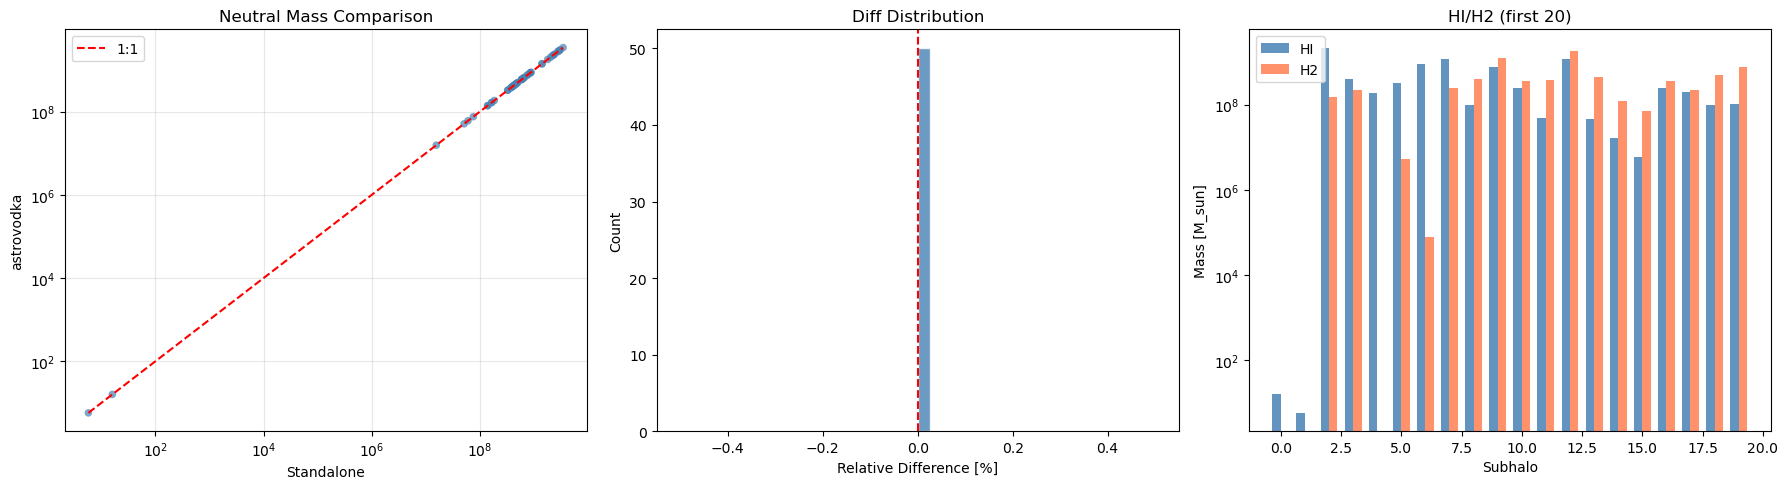

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examplefigure/mass_comparison.png


In [9]:
if len(mass_comparisons) > 0:
    mc=mass_comparisons
    neutral_a=np.array([m['m_neutral_astrovodka'] for m in mc])
    neutral_s=np.array([m['m_neutral_standalone'] for m in mc])
    hi_a=np.array([m['m_HI_astrovodka'] for m in mc])
    h2_a=np.array([m['m_H2_astrovodka'] for m in mc])
    rel_diff=np.abs(neutral_a-neutral_s)/np.maximum(neutral_a,1e-30)
    
    fig,axes=plt.subplots(1,3,figsize=(18,5))
    ax=axes[0]; ax.scatter(neutral_s,neutral_a,c='steelblue',alpha=0.7,s=30,edgecolors='none')
    lims=[min(neutral_s.min(),neutral_a.min()),max(neutral_s.max(),neutral_a.max())]
    ax.plot(lims,lims,'r--',lw=1.5,label='1:1')
    ax.set(xlabel='Standalone',ylabel='astrovodka',title='Neutral Mass Comparison',
           xscale='log',yscale='log'); ax.legend(); ax.grid(alpha=0.3)
    
    ax=axes[1]; ax.hist(rel_diff*100,bins=40,color='steelblue',edgecolor='white',alpha=0.8)
    ax.set(xlabel='Relative Difference [%]',ylabel='Count',title='Diff Distribution')
    ax.axvline(0,color='red',ls='--',lw=1.5)
    
    ax=axes[2]; n_show=min(20,len(mc)); x=np.arange(n_show); w=0.35
    ax.bar(x-w/2,hi_a[:n_show],w,label='HI',color='steelblue',alpha=0.85)
    ax.bar(x+w/2,h2_a[:n_show],w,label='H2',color='coral',alpha=0.85)
    ax.set(xlabel='Subhalo',ylabel='Mass [M_sun]',title=f'HI/H2 (first {n_show})')
    ax.legend(); ax.set_yscale('log')
    
    plt.tight_layout(); fpath=os.path.join(FIG_DIR,'mass_comparison.png')
    plt.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white'); plt.show()
    print(f'Saved: {fpath}')

## 任务三：数据立方体可视化

Moment 0 (积分强度), Moment 1 (速度场), 全局光谱, 通道图

In [10]:
def compute_moments(cube_data):
    mom0=np.sum(cube_data,axis=0); nchan=cube_data.shape[0]
    with np.errstate(invalid='ignore',divide='ignore'):
        mom1=np.sum(cube_data*np.arange(nchan)[:,np.newaxis,np.newaxis],axis=0)/np.maximum(mom0,1e-30)
    mom1[~np.isfinite(mom1)]=np.nan; return mom0,mom1

def visualize_cube(fits_path, title_prefix='', save=True):
    with fits.open(fits_path) as hdul:
        data=hdul[0].data; header=hdul[0].header; wcs=WCS(header).celestial
    mom0,mom1=compute_moments(data); rms=np.std(data[0]); signal_mask=mom0>3*rms
    nchan=data.shape[0]; peak_chan=np.argmax(np.sum(data,axis=(1,2)))
    chans=sorted(set([max(0,peak_chan-3),peak_chan,min(nchan-1,peak_chan+3)]))
    fig=plt.figure(figsize=(18,8)); gs=gridspec.GridSpec(2,3,figure=fig,hspace=0.35,wspace=0.3)
    
    ax0=fig.add_subplot(gs[0,0],projection=wcs)
    vmax=np.percentile(mom0[signal_mask],95) if signal_mask.any() else mom0.max()
    ax0.imshow(mom0,origin='lower',cmap='inferno',vmin=0,vmax=vmax)
    ax0.set(xlabel='RA',ylabel='Dec',title='Moment 0')
    
    ax1=fig.add_subplot(gs[0,1],projection=wcs)
    m1m=np.where(signal_mask,mom1,np.nan)
    ax1.imshow(m1m,origin='lower',cmap='RdBu_r',vmin=np.nanpercentile(m1m,10),vmax=np.nanpercentile(m1m,90))
    ax1.set(xlabel='RA',ylabel='Dec',title='Moment 1')
    
    ax_spec=fig.add_subplot(gs[0,2]); spectrum=np.sum(data,axis=(1,2))
    ax_spec.plot(np.arange(nchan),spectrum,'k-',lw=1.5); ax_spec.fill_between(np.arange(nchan),0,spectrum,alpha=0.3,color='steelblue')
    ax_spec.set(xlabel='Channel',ylabel='Total Flux',title='Global Spectrum')
    ax_spec.axvline(peak_chan,color='red',ls='--',lw=1,label=f'Peak ch={peak_chan}'); ax_spec.legend()
    
    for i,ch in enumerate(chans):
        ax=fig.add_subplot(gs[1,i],projection=wcs); ch_data=data[ch]
        ax.imshow(ch_data,origin='lower',cmap='inferno',vmin=0,vmax=np.percentile(ch_data,99))
        ax.set(xlabel='RA',ylabel='Dec',title=f'Channel {ch}'+(' *' if ch==peak_chan else ''))
    
    plt.suptitle(title_prefix,fontsize=15,fontweight='bold',y=1.02)
    if save:
        fname=title_prefix.replace(' ','_').replace(':','').replace('=','_')+'.png'
        fpath=os.path.join(FIG_DIR,fname)
        plt.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')
    plt.show()
print('可视化函数定义完成')

可视化函数定义完成


### 同一星系在三个红移的对比

全部3个红移: 49 个


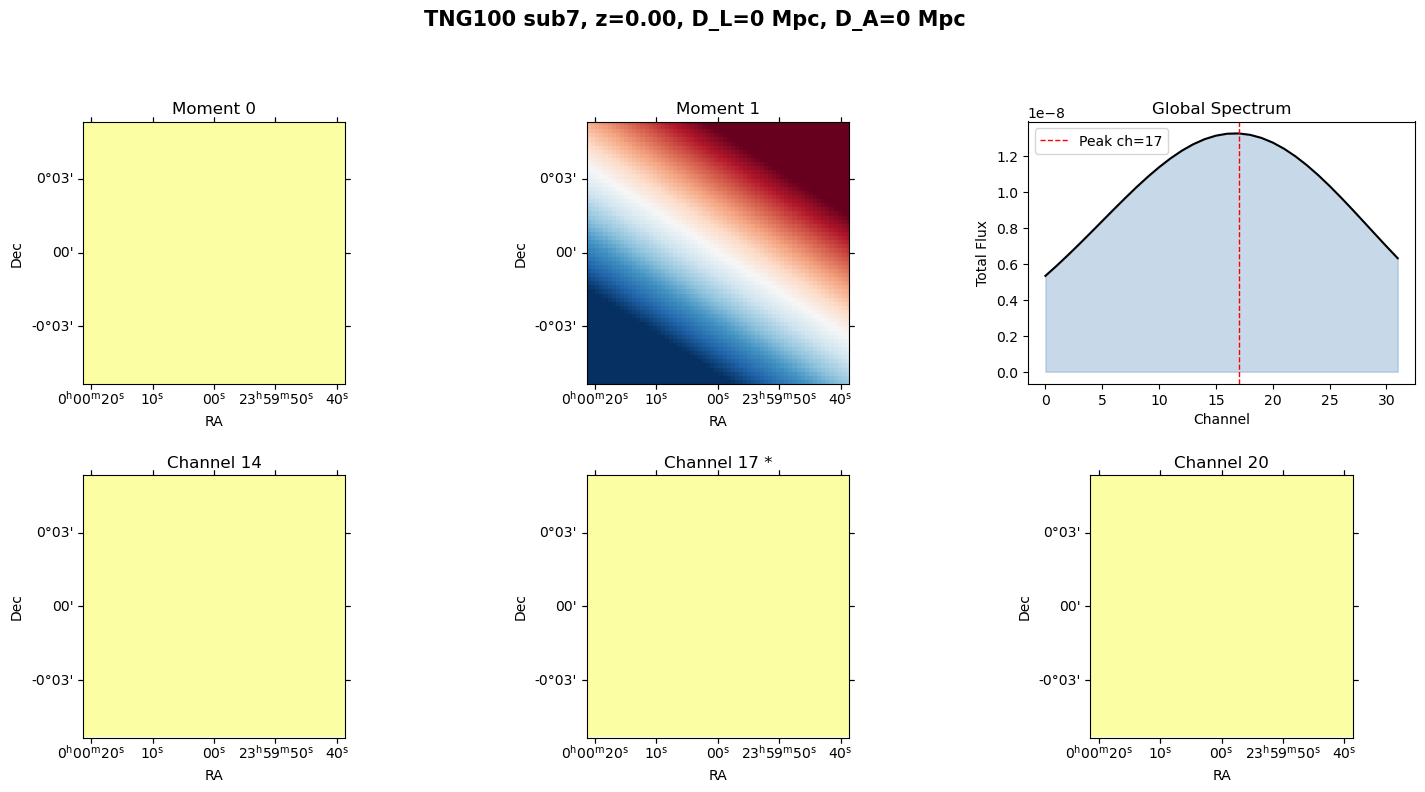

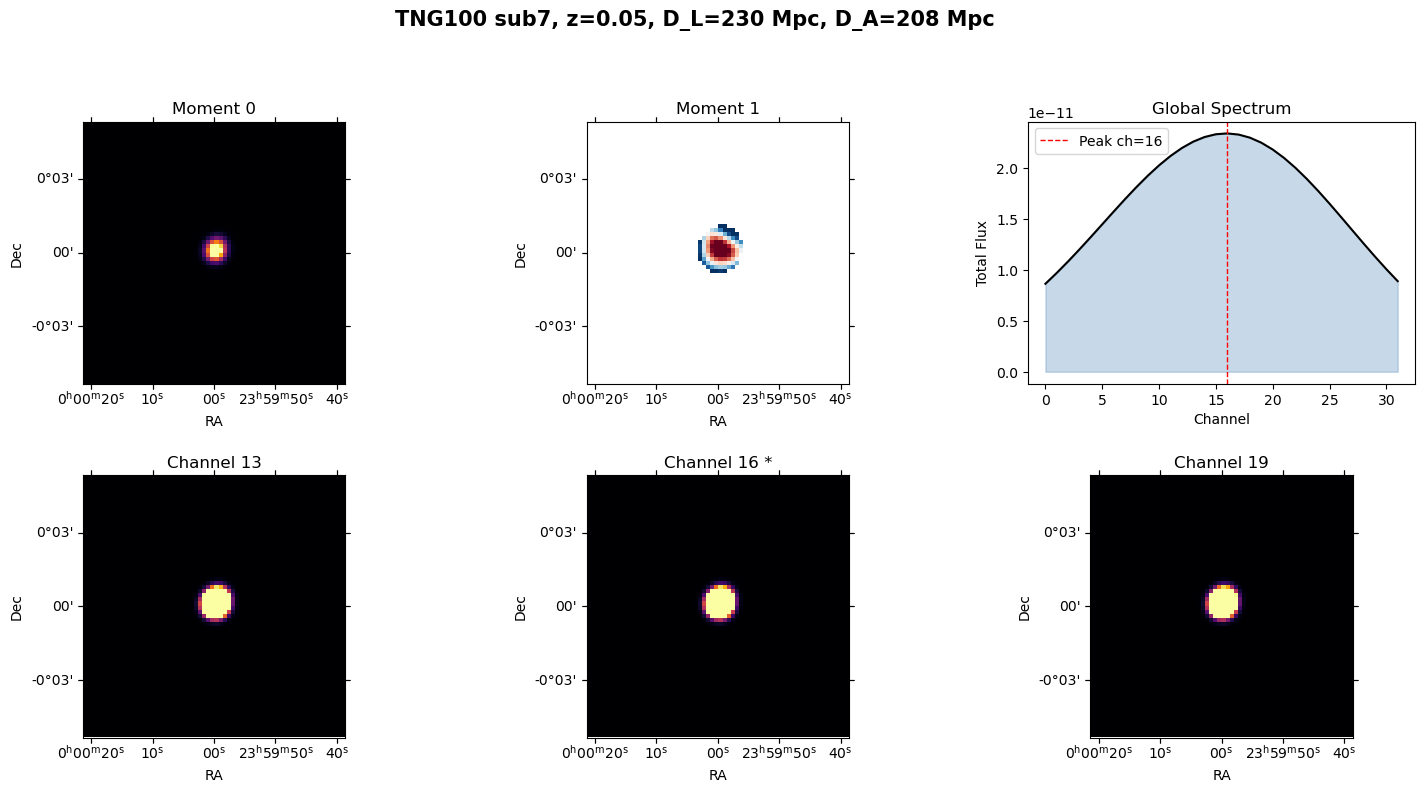

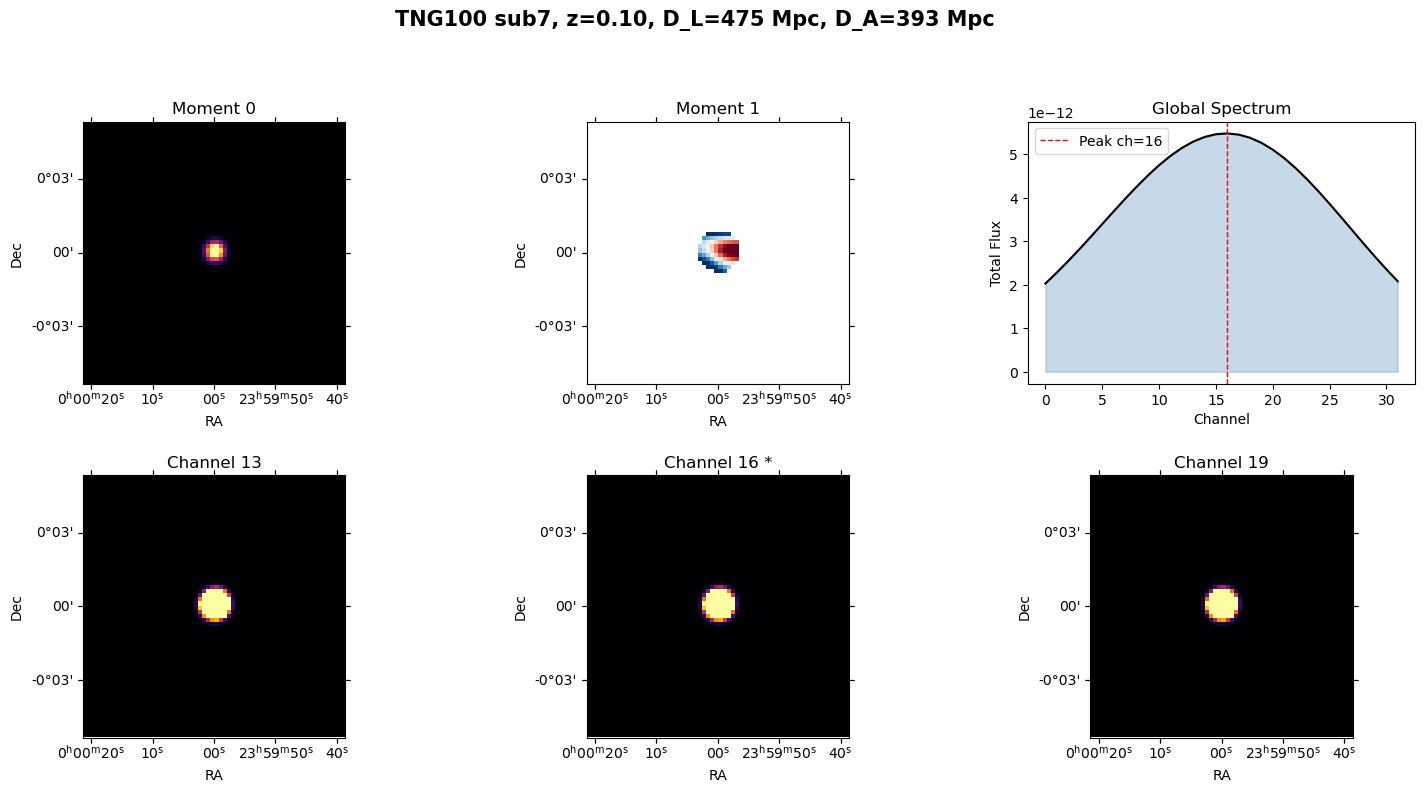

In [11]:
if len(results) > 0:
    sub_counts=Counter(r['subID'] for r in results)
    complete=[sid for sid,cnt in sub_counts.items() if cnt>=3]
    print(f'全部3个红移: {len(complete)} 个')
    if len(complete)>0:
        demo=complete[0]
        for z_obs in OBSERVED_REDSHIFTS:
            fpath=os.path.join(DATA_DIR,f'TNG100_snap{snapNum}_sub{demo:07d}_z{z_obs:.2f}.fits')
            if os.path.exists(fpath):
                DL=luminosity_distance(z_obs); DA=angular_diameter_distance(z_obs)
                visualize_cube(fpath,title_prefix=f'TNG100 sub{demo}, z={z_obs:.2f}, D_L={DL:.0f}, D_A={DA:.0f}',save=True)
    else:
        # 没有子暗晕在所有3个红移都被成功处理
        # 显示每个红移中最大的子暗晕
        print('没有子暗晕在全部3个红移被成功处理(小卫星星系在10"分辨率不可分辨)' )
        print('\\n改为显示每个红移中HI质量最大的子暗晕:')
        for z_obs in OBSERVED_REDSHIFTS:
            z_results = [r for r in results if r['z_obs'] == z_obs]
            if z_results:
                best = max(z_results, key=lambda r: r.get('m_HI_msun', 0))
                DL = luminosity_distance(z_obs); DA = angular_diameter_distance(z_obs)
                if os.path.exists(best['file']):
                    visualize_cube(best['file'],
                        title_prefix=f'Best z={z_obs:.2f}: sub{best["subID"]}, D_L={DL:.0f}, D_A={DA:.0f}',
                        save=True)
            else:
                print(f'  z={z_obs:.2f}: 无成功的数据立方体')

### 最大 HI 质量子暗晕

Max HI: subhalo 122 z_obs=0.00, M_HI=3.14e+09 M_sun


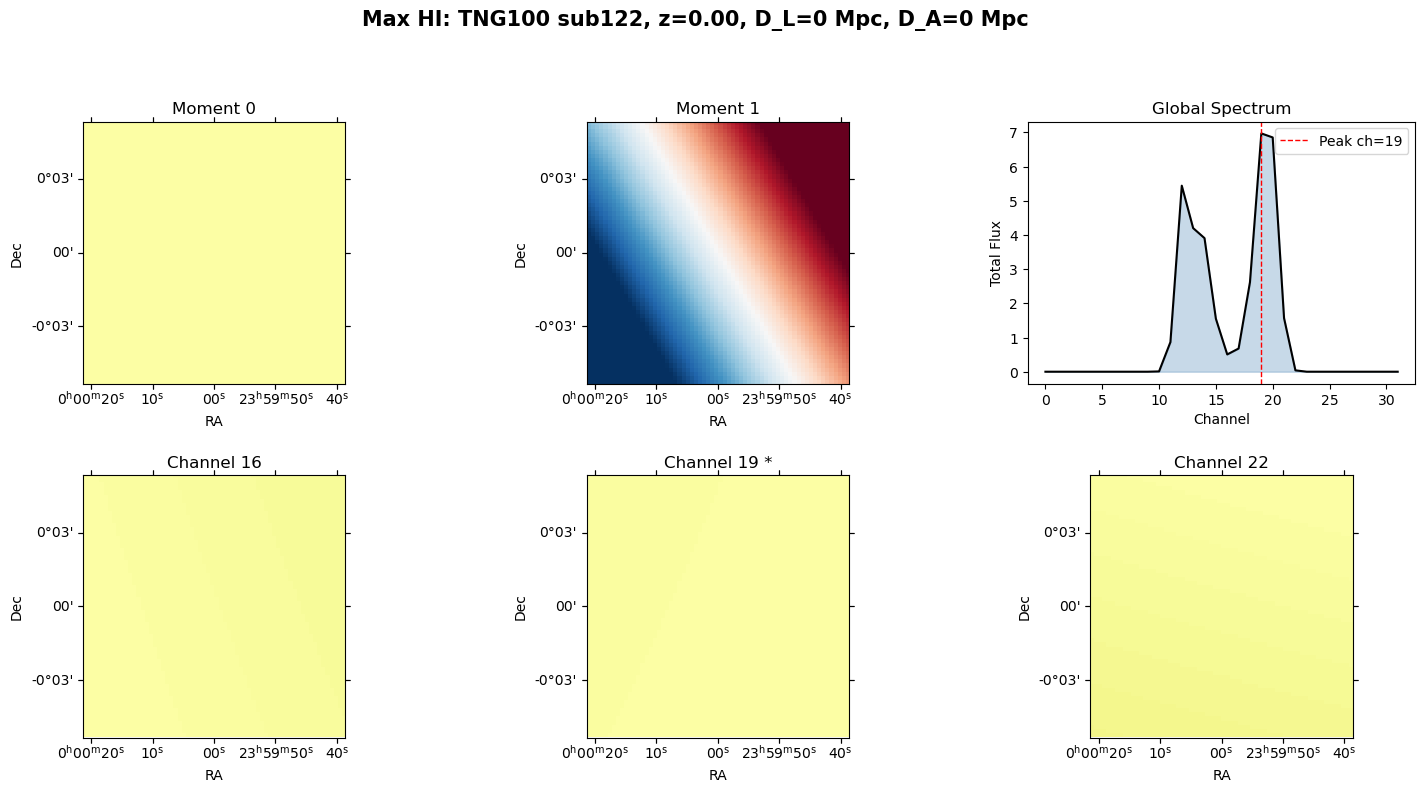

In [12]:
if len(results) > 0:
    best=max(results,key=lambda r:r.get('m_HI_msun',0))
    print(f'Max HI: subhalo {best["subID"]} z_obs={best["z_obs"]:.2f}, M_HI={best["m_HI_msun"]:.2e} M_sun')
    if os.path.exists(best['file']):
        z=best['z_obs']; DL=luminosity_distance(z); DA=angular_diameter_distance(z)
        visualize_cube(best['file'],title_prefix=f'Max HI: TNG100 sub{best["subID"]}, z={z:.2f}, D_L={DL:.0f}, D_A={DA:.0f}',save=True)
else:
    print('No data cubes were generated successfully.')
    print('This can happen when all selected subhalos are too small to resolve at 10" resolution.')

## 总结

| 任务 | 内容 |
|------|------|
| 一 | 50 subhalos x 3 redshifts |
| 二 | K13 质量方法一致性检验 |
| 三 | Moment maps + 光谱 + 通道图 |

In [13]:
print('='*60); print('  Summary'); print('='*60)
print(f'  Subhalos: {len(target_ids)}, Redshifts: {OBSERVED_REDSHIFTS}')
print(f'  Cubes: {len(results)}, Mass comparisons: {len(mass_comparisons)}')
print(f'  Data: {DATA_DIR}'); print(f'  Figures: {FIG_DIR}')
if len(mass_comparisons)>0:
    na=np.array([m['m_neutral_astrovodka'] for m in mass_comparisons])
    ns=np.array([m['m_neutral_standalone'] for m in mass_comparisons])
    agree=np.allclose(na,ns,rtol=1e-10)
    print(f'  K13 methods agree: {agree}')
    if agree: print('  => astrovodka K13 implementation CORRECT')
print('Done!')

  Summary
  Subhalos: 50, Redshifts: [0.0, 0.05, 0.1]
  Cubes: 149, Mass comparisons: 50
  Data: /data/hw2/projects/FAST/HD2_high/astrovodka/datafile/
  Figures: /home/zerui603/work/astrovodka/astrovodka.0.1/examplefigure/
  K13 methods agree: True
  => astrovodka K13 implementation CORRECT
Done!
